Lets try to understand each column and its use case when it comes to this anlysis . 

01. store dimension

In [25]:
import pandas as pd
from pathlib import Path
import numpy as np 

# Dynamically resolve project root
current_path = Path.cwd().resolve()
project_root = None
for p in [current_path] + list(current_path.parents):
    if (p / "inventory-lakehouse").is_dir():
        project_root = p
        break

if project_root is None:
    project_root = Path("D:/Demand_forecasting").resolve()

lakehouse_root = project_root / "inventory-lakehouse"


In [34]:
store_dimension_df = pd.read_parquet(lakehouse_root / "data_lake" / "silver" / "store_dimension" / "store_dimension.parquet")

In [27]:
store_dimension_df.head()

,store_id,city,state,store_type,cluster
0,1,Quito,Pichincha,D,13
1,2,Quito,Pichincha,D,13
2,3,Quito,Pichincha,D,8
3,4,Quito,Pichincha,D,9
4,5,Santo Domingo,Santo Domingo de los Tsachilas,D,4


In [28]:
store_dimension_df['city'].unique()

array(['Quito', 'Santo Domingo', 'Cayambe', 'Latacunga', 'Riobamba',
       'Ibarra', 'Guaranda', 'Puyo', 'Ambato', 'Guayaquil', 'Salinas',
       'Daule', 'Babahoyo', 'Quevedo', 'Playas', 'Libertad', 'Cuenca',
       'Loja', 'Machala', 'Esmeraldas', 'Manta', 'El Carmen'],
      dtype=object)

In [29]:
store_dimension_df['state'].unique()

array(['Pichincha', 'Santo Domingo de los Tsachilas', 'Cotopaxi',
       'Chimborazo', 'Imbabura', 'Bolivar', 'Pastaza', 'Tungurahua',
       'Guayas', 'Santa Elena', 'Los Rios', 'Azuay', 'Loja', 'El Oro',
       'Esmeraldas', 'Manabi'], dtype=object)

In [30]:
store_dimension_df['store_type'].unique()

array(['D', 'B', 'C', 'E', 'A'], dtype=object)

In [31]:
store_dimension_df['cluster'].unique()

array([13,  8,  9,  4,  6, 15,  7,  3, 12, 16,  1, 10,  2,  5, 11, 14, 17],
      dtype=int32)

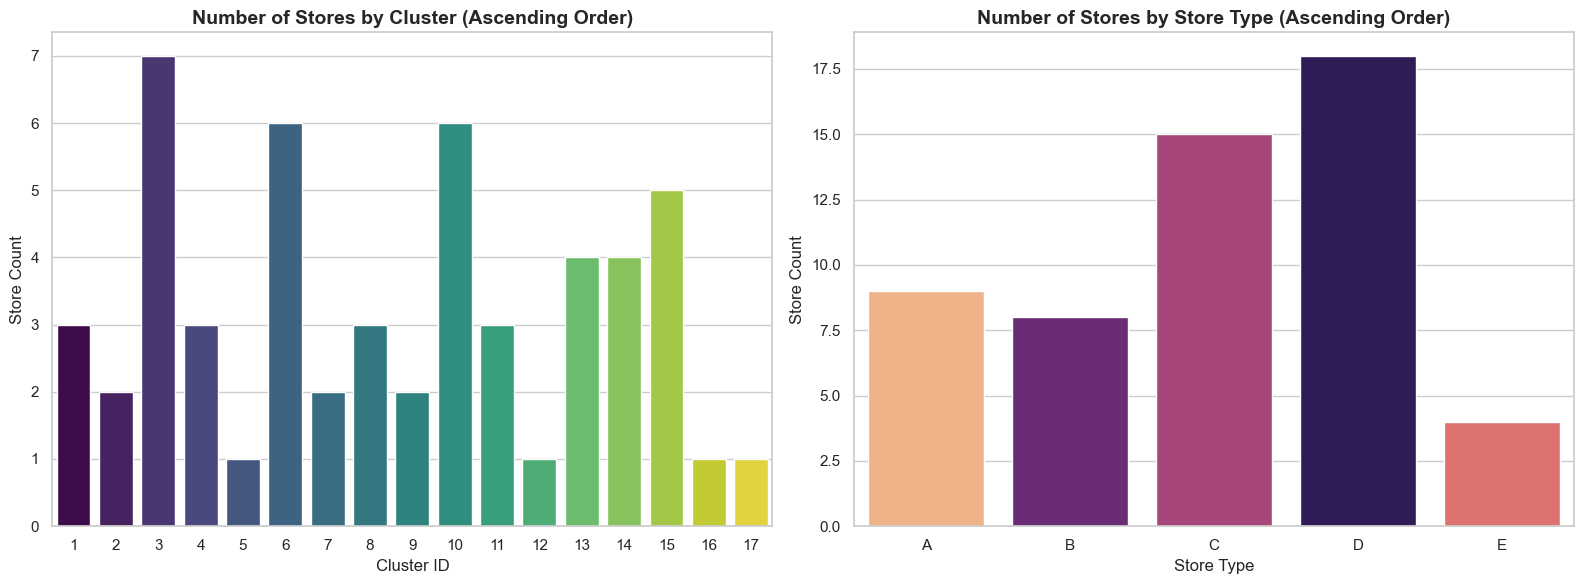

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for professional aesthetic
sns.set_theme(style="whitegrid")

# Create a figure with two subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Number of stores by cluster (sorted in ascending order numerically)
sns.countplot(
    data=store_dimension_df, 
    x="cluster", 
    hue="cluster",
    ax=axes[0], 
    palette="viridis",
    legend=False,
    order=sorted(store_dimension_df["cluster"].unique())
)
axes[0].set_title("Number of Stores by Cluster (Ascending Order)", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Cluster ID", fontsize=12)
axes[0].set_ylabel("Store Count", fontsize=12)

# Plot 2: Number of stores by store_type (sorted in ascending order alphabetically)
sns.countplot(
    data=store_dimension_df, 
    x="store_type", 
    hue="store_type",
    ax=axes[1], 
    palette="magma",
    legend=False,
    order=sorted(store_dimension_df["store_type"].unique())
)
axes[1].set_title("Number of Stores by Store Type (Ascending Order)", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Store Type", fontsize=12)
axes[1].set_ylabel("Store Count", fontsize=12)

plt.tight_layout()
plt.show()


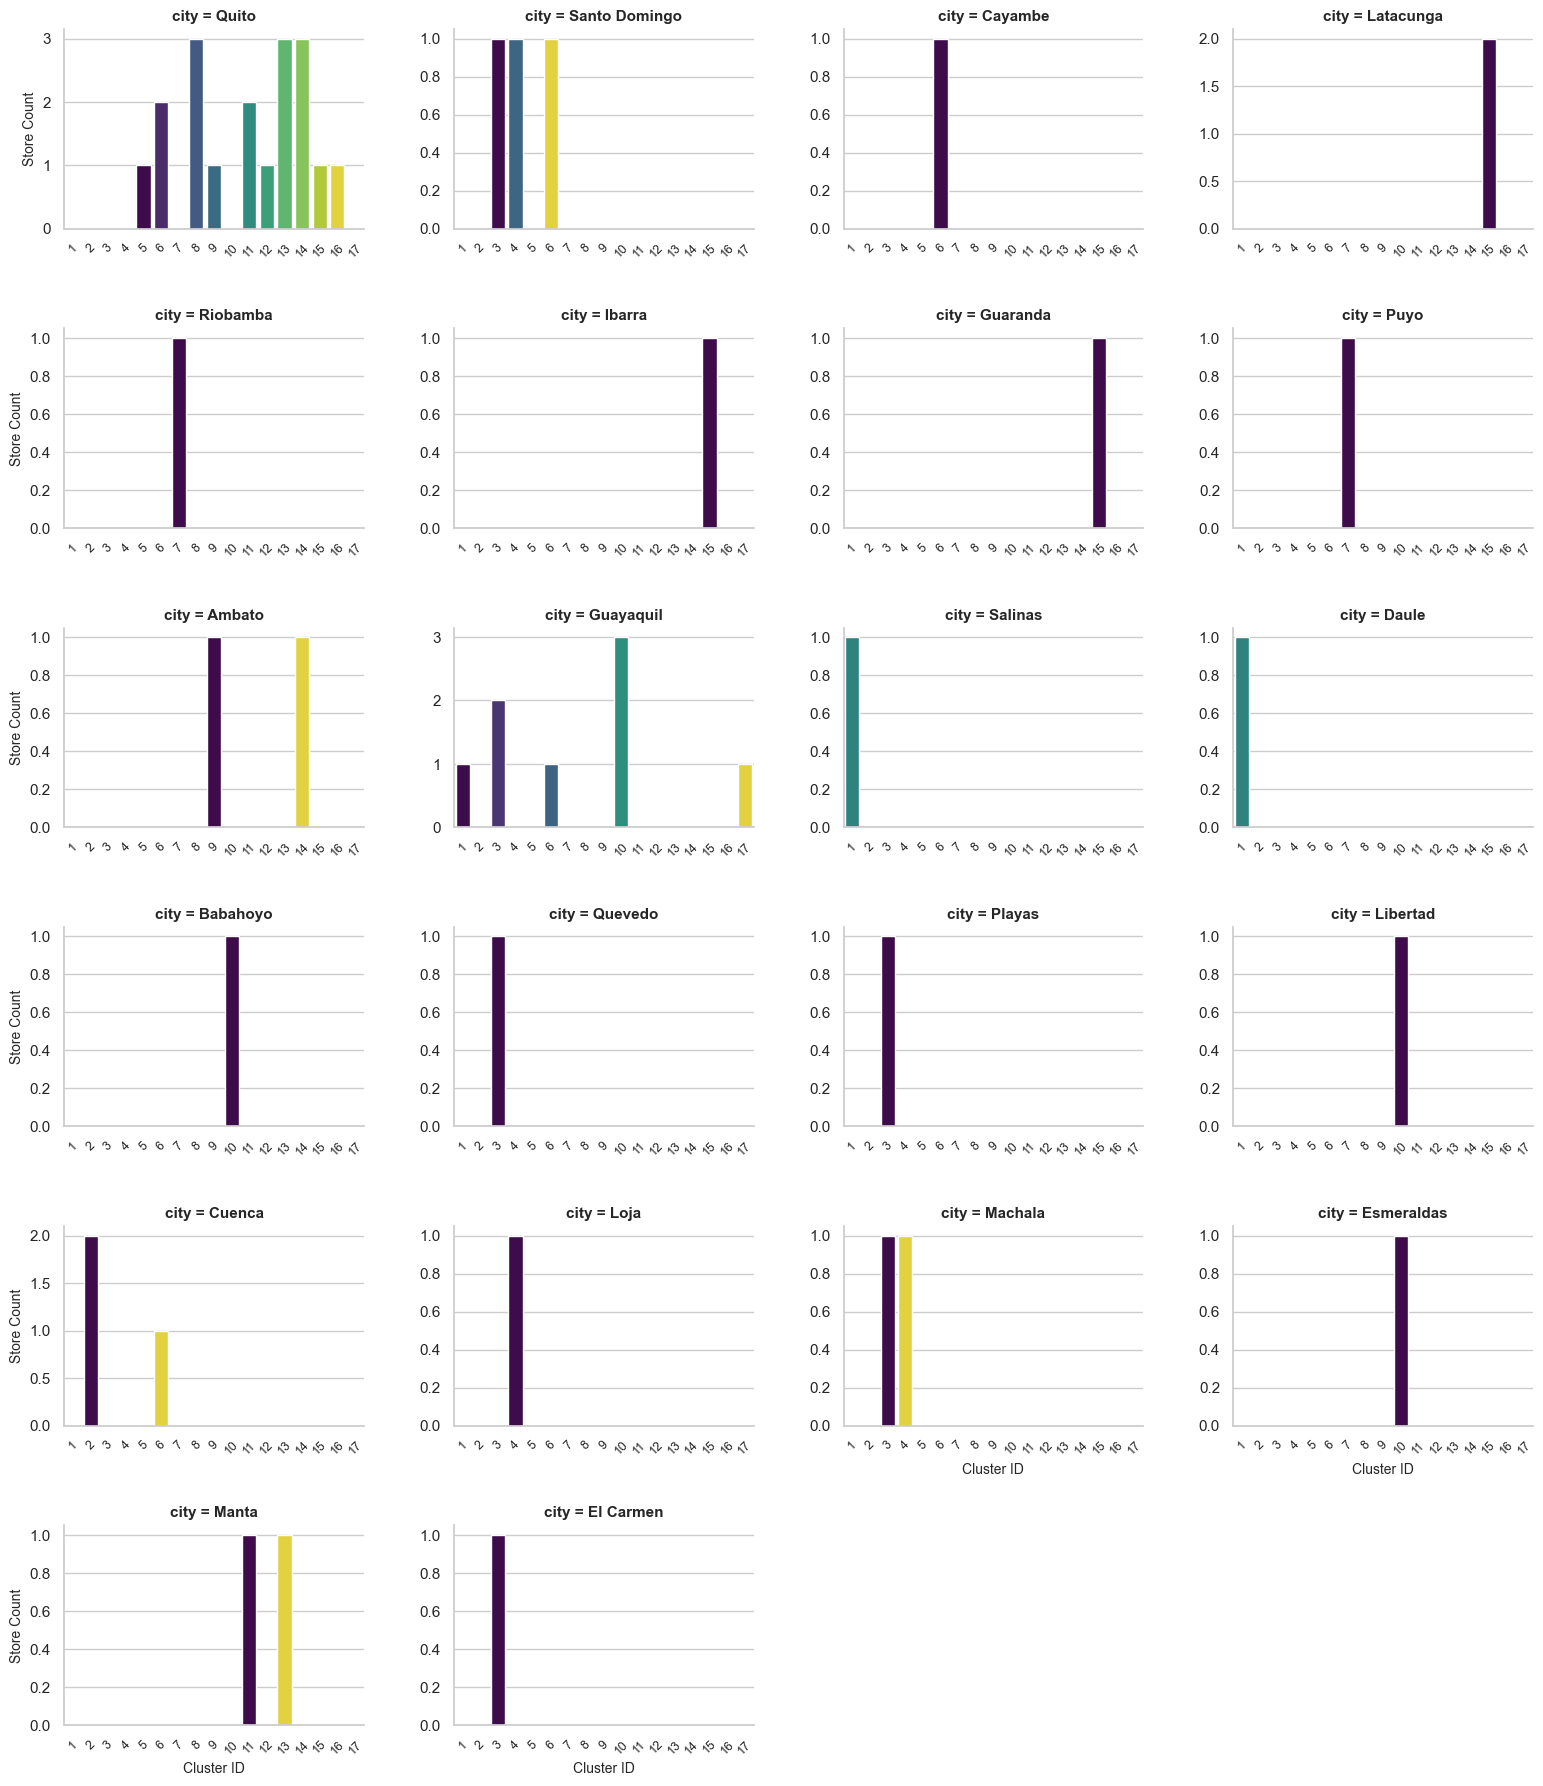

In [33]:
# Create a grid of subplots (FacetGrid) to analyze cluster density/distribution for each city
import matplotlib.pyplot as plt
import seaborn as sns

# Set theme style
sns.set_theme(style="whitegrid")

# Create FacetGrid (4 subplots per row)
g = sns.FacetGrid(
    store_dimension_df, 
    col="city", 
    col_wrap=4, 
    sharex=True, 
    sharey=False, 
    height=3, 
    aspect=1.3
)

# Plot count of stores for each cluster inside each city
g.map_dataframe(
    sns.countplot, 
    x="cluster", 
    hue="cluster",
    palette="viridis",
    legend=False,
    order=sorted(store_dimension_df["cluster"].unique())
)

# Customizations for readability without warnings
for ax in g.axes.flat:
    ax.tick_params(labelbottom=True)
    ax.tick_params(axis='x', rotation=45, labelsize=9)
    ax.set_title(ax.get_title(), fontsize=11, fontweight="bold")

g.set_axis_labels("Cluster ID", "Store Count", fontsize=10)
plt.subplots_adjust(hspace=0.5, wspace=0.3)
plt.show()


02. Oil dimension 

In [36]:
oil_dimension_df = pd.read_parquet(lakehouse_root / "data_lake" / "silver" / "oil_dimension" / "oil_dimension.parquet")


In [37]:
oil_dimension_df.head()

,date,oil_price,oil_price_change,oil_7d_avg
0,2013-01-01,93.14,0.00,93.140000
1,2013-01-02,93.14,0.00,93.140000
2,2013-01-03,92.97,-0.17,93.083333
3,2013-01-04,93.12,0.15,93.092500
4,2013-01-05,93.12,0.00,93.098000


02. Oil Dimension 


Loading oil_dimension dataset...


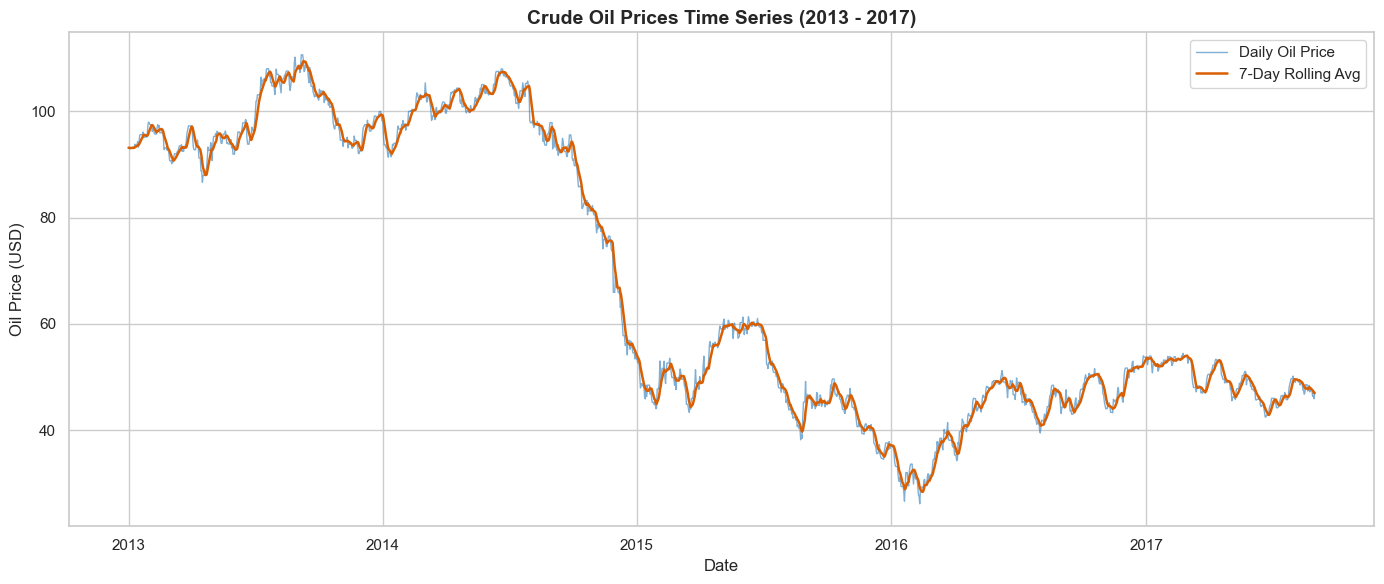

In [38]:
# 02. oil dimension
# Load and plot crude oil price time series
import matplotlib.pyplot as plt
import seaborn as sns

print("Loading oil_dimension dataset...")
oil_dimension_df = pd.read_parquet(lakehouse_root / "data_lake" / "silver" / "oil_dimension" / "oil_dimension.parquet")
oil_dimension_df['date'] = pd.to_datetime(oil_dimension_df['date'])

# Set plot style
sns.set_theme(style="whitegrid")

# Create figure
plt.figure(figsize=(14, 6))

# Plot daily price and 7-day rolling average
sns.lineplot(
    data=oil_dimension_df, 
    x="date", 
    y="oil_price", 
    label="Daily Oil Price", 
    color="#2b7bba", 
    alpha=0.6,
    linewidth=1
)
sns.lineplot(
    data=oil_dimension_df, 
    x="date", 
    y="oil_7d_avg", 
    label="7-Day Rolling Avg", 
    color="#d95f02", 
    linewidth=1.8
)

plt.title("Crude Oil Prices Time Series (2013 - 2017)", fontsize=14, fontweight="bold")
plt.xlabel("Date", fontsize=12)
plt.ylabel("Oil Price (USD)", fontsize=12)
plt.legend(fontsize=11, loc="upper right")
plt.tight_layout()
plt.show()
